# Resume Keyword Extraction using NLP

A beginner-friendly notebook that reuses the techniques practiced in lab experiments 2–10. Run the cells from top to bottom.

## 1. Setup — experiment 2 (text preprocessing)
This section imports the libraries used later. If a required package or language model is missing, install the packages and spaCy model using the commands shown here, then restart the kernel. NLTK data resources are checked in the setup cell.

In [1]:
# If needed, run these commands in a terminal before opening the notebook:
# pip install nltk spacy scikit-learn pandas matplotlib wordcloud streamlit
# python -m spacy download en_core_web_sm

import re
import html
from pathlib import Path
from collections import Counter

import pandas as pd
import nltk
import spacy
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS
from nltk.corpus import stopwords, wordnet
from nltk.tokenize import RegexpTokenizer
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag
from nltk.chunk import RegexpParser
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Download only standard NLTK language resources if they are not already available.
for resource in ["corpora/stopwords", "corpora/wordnet", "taggers/averaged_perceptron_tagger_eng"]:
    try:
        nltk.data.find(resource)
    except LookupError:
        package = resource.split("/")[-1]
        if package == "stopwords":
            nltk.download("stopwords", quiet=True)
        elif package == "wordnet":
            nltk.download("wordnet", quiet=True)
        else:
            nltk.download("averaged_perceptron_tagger_eng", quiet=True)

# Load spaCy's small English model. Install it using the command above if unavailable.
nlp = spacy.load("en_core_web_sm")
DATA_PATH = Path("data/UpdatedResumeDataSet.csv")
CLEAN_PATH = Path("data/resumes_clean.csv")
FIGURE_DIR = Path("outputs/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
print("Libraries loaded. spaCy model:", nlp.meta["name"])
print("Input file exists:", DATA_PATH.exists())


Libraries loaded. spaCy model: core_web_sm
Input file exists: True


## 2. Load data and inspect — experiments 1 and 10
We load the supplied CSV and inspect its dimensions, columns, missing values, category counts, duplicate resumes, and a short text sample. This gives a baseline before cleaning.

In [2]:
# Read the original dataset without changing it.
df = pd.read_csv(DATA_PATH, encoding="utf-8", encoding_errors="replace")
print("Rows and columns:", df.shape)
print("Columns:", list(df.columns))
print("Missing values:\n", df[["Category", "Resume"]].isna().sum())
print("Exact duplicate resume rows after first copy:", int(df["Resume"].duplicated().sum()))
print("Number of categories:", df["Category"].nunique())
print("Top category counts:\n", df["Category"].value_counts().head(10).to_string())
print("\nSample category:", df.loc[0, "Category"])
print("Sample resume excerpt:\n", str(df.loc[0, "Resume"])[:500])
# Count common signs of broken text encoding so they can be reviewed.
artifact_pattern = re.compile(r"Ã|â|�")
print("Rows with likely encoding artifacts:", int(df["Resume"].fillna("").map(lambda x: bool(artifact_pattern.search(str(x)))).sum()))


Rows and columns: (962, 2)
Columns: ['Category', 'Resume']
Missing values:
 Category    0
Resume      0
dtype: int64
Exact duplicate resume rows after first copy: 796
Number of categories: 25
Top category counts:
 Category
Java Developer         84
Testing                70
DevOps Engineer        55
Python Developer       48
Web Designing          45
HR                     44
Hadoop                 42
Data Science           40
Mechanical Engineer    40
Sales                  40

Sample category: Data Science
Sample resume excerpt:
 Skills * Programming Languages: Python (pandas, numpy, scipy, scikit-learn, matplotlib), Sql, Java, JavaScript/JQuery. * Machine learning: Regression, SVM, NaÃ¯ve Bayes, KNN, Random Forest, Decision Trees, Boosting techniques, Cluster Analysis, Word Embedding, Sentiment Analysis, Natural Language processing, Dimensionality reduction, Topic Modelling (LDA, NMF), PCA & Neural Nets. * Database Visualizations: Mysql, SqlServer, Cassandra, Hbase, ElasticSearch D3

## 3. Remove duplicates and clean text — experiment 2
Experiment 2 tokenized text and filtered obvious noise. Here we remove exact duplicate resume texts first, normalize whitespace and common encoding artifacts, and preserve useful skill forms such as C++, C#, .NET, and scikit-learn. The unique resumes are saved to `data/resumes_clean.csv`; the source file stays untouched.

In [3]:
# Keep one row for each exact resume text before cleaning.
unique_df = df.drop_duplicates(subset="Resume", keep="first").copy()
tokenizer = RegexpTokenizer(r"(?i)(?:c\+\+|c#|\.net|scikit-learn|[a-z][a-z0-9+#.]*)(?:[-'][a-z0-9+#.]+)*")

def basic_clean(text):
    """Decode HTML entities, normalize common mojibake, and tokenize useful terms."""
    text = html.unescape(str(text))
    text = text.replace("NaÃ¯ve", "Naive").replace("naÃ¯ve", "naive")
    text = re.sub(r"â\s*\s*¢|â€¢|•", " ", text)
    text = re.sub(r"\s+", " ", text).strip().lower()
    return " ".join(tokenizer.tokenize(text))

unique_df["Filtered_Resume"] = unique_df["Resume"].fillna("").map(basic_clean)
unique_df.to_csv(CLEAN_PATH, index=False, encoding="utf-8")
print("Original rows:", len(df))
print("Unique resumes:", len(unique_df))
print("Duplicate rows removed:", len(df) - len(unique_df))
print("Saved cleaned data to:", CLEAN_PATH)
print("Columns saved:", list(unique_df.columns))
print("Cleaned text sample:\n", unique_df["Filtered_Resume"].iloc[0][:450])


Original rows: 962
Unique resumes: 166
Duplicate rows removed: 796
Saved cleaned data to: data\resumes_clean.csv
Columns saved: ['Category', 'Resume', 'Filtered_Resume']
Cleaned text sample:
 skills programming languages python pandas numpy scipy scikit-learn matplotlib sql java javascript jquery. machine learning regression svm naive bayes knn random forest decision trees boosting techniques cluster analysis word embedding sentiment analysis natural language processing dimensionality reduction topic modelling lda nmf pca neural nets. database visualizations mysql sqlserver cassandra hbase elasticsearch d3.js dc.js plotly kibana matpl


## 4. Stopword removal and lemmatization — experiment 3
Experiment 3 compared original words with stopword-filtered and normalized forms. This section removes common English stopwords and lemmatizes each token. We update the same cleaned CSV with the normalized text for later stages.

In [4]:
english_stopwords = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def normalize_tokens(text):
    """Remove stopwords and lemmatize the remaining tokens."""
    tokens = tokenizer.tokenize(str(text).lower())
    return [lemmatizer.lemmatize(word) for word in tokens if word not in english_stopwords]

unique_df["Tokens"] = unique_df["Filtered_Resume"].map(normalize_tokens)
unique_df["Cleaned_Resume"] = unique_df["Tokens"].map(lambda words: " ".join(words))
unique_df.to_csv(CLEAN_PATH, index=False, encoding="utf-8")
print("Stopwords removed and words lemmatized.")
print("Before:", unique_df["Filtered_Resume"].iloc[0][:250])
print("After: ", unique_df["Cleaned_Resume"].iloc[0][:250])
print("Normalized token count in sample:", len(unique_df["Tokens"].iloc[0]))


Stopwords removed and words lemmatized.
Before: skills programming languages python pandas numpy scipy scikit-learn matplotlib sql java javascript jquery. machine learning regression svm naive bayes knn random forest decision trees boosting techniques cluster analysis word embedding sentiment anal
After:  skill programming language python panda numpy scipy scikit-learn matplotlib sql java javascript jquery. machine learning regression svm naive bayes knn random forest decision tree boosting technique cluster analysis word embedding sentiment analysis 
Normalized token count in sample: 491


## 5. POS tagging, morphology, and noun phrases — experiments 4, 6, and 7
Experiments 4 and 6 used part-of-speech (POS) tags to study word forms, while experiment 7 grouped tagged words into noun phrases. We show sample tags and simple noun-phrase chunks; these are candidate phrases and may need human review.

In [5]:
# Map NLTK tags to WordNet's noun, verb, adjective, or adverb labels.
def wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    if tag.startswith("V"):
        return wordnet.VERB
    if tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

sample_words = tokenizer.tokenize(str(unique_df["Filtered_Resume"].iloc[0]))[:35]
sample_tags = pos_tag(sample_words)
print("Sample POS tags:", sample_tags)
print("Morphology examples:", [(word, lemmatizer.lemmatize(word, wordnet_pos(tag))) for word, tag in sample_tags[:12]])

# A simple grammar for adjective(s) followed by one or more nouns.
chunker = RegexpParser("NP: {<JJ.*>*<NN.*>+}")
chunk_tree = chunker.parse(sample_tags)
phrases = [" ".join(word for word, tag in subtree.leaves()) for subtree in chunk_tree.subtrees() if subtree.label() == "NP"]
print("Noun phrase candidates:", phrases[:20])

# Extract phrase candidates for every resume using the same grammar.
def noun_phrases(text):
    words = tokenizer.tokenize(str(text))[:4000]
    tagged = pos_tag(words)
    tree = chunker.parse(tagged)
    return [" ".join(word for word, tag in subtree.leaves()) for subtree in tree.subtrees() if subtree.label() == "NP"]
unique_df["Noun_Phrases"] = unique_df["Filtered_Resume"].map(noun_phrases)


Sample POS tags: [('skills', 'NNS'), ('programming', 'VBG'), ('languages', 'NNS'), ('python', 'VBP'), ('pandas', 'JJ'), ('numpy', 'JJ'), ('scipy', 'NN'), ('scikit-learn', 'JJ'), ('matplotlib', 'NN'), ('sql', 'NN'), ('java', 'NN'), ('javascript', 'NN'), ('jquery.', 'NN'), ('machine', 'NN'), ('learning', 'VBG'), ('regression', 'NN'), ('svm', 'FW'), ('naive', 'JJ'), ('bayes', 'NNS'), ('knn', 'VBP'), ('random', 'JJ'), ('forest', 'JJS'), ('decision', 'NN'), ('trees', 'NNS'), ('boosting', 'VBG'), ('techniques', 'NNS'), ('cluster', 'NN'), ('analysis', 'NN'), ('word', 'NN'), ('embedding', 'VBG'), ('sentiment', 'NN'), ('analysis', 'NN'), ('natural', 'JJ'), ('language', 'NN'), ('processing', 'NN')]
Morphology examples: [('skills', 'skill'), ('programming', 'program'), ('languages', 'language'), ('python', 'python'), ('pandas', 'pandas'), ('numpy', 'numpy'), ('scipy', 'scipy'), ('scikit-learn', 'scikit-learn'), ('matplotlib', 'matplotlib'), ('sql', 'sql'), ('java', 'java'), ('javascript', 'javasc

## 6. Named entity recognition and skills list — experiment 8
Experiment 8 explored named entity recognition (NER). spaCy can identify people, organizations, places, and dates, but a general model may miss technical skills. We therefore also search for a small transparent list of common skills.

In [6]:
# This editable list makes the skill matching easy to explain and extend.
COMMON_SKILLS = [
    "python", "java", "sql", "c++", "c#", ".net", "javascript", "html", "css",
    "machine learning", "deep learning", "natural language processing", "data analysis",
    "scikit-learn", "pandas", "numpy", "tensorflow", "pytorch", "spacy", "nltk",
    "excel", "tableau", "power bi", "aws", "azure", "docker", "kubernetes",
    "git", "linux", "hadoop", "spark", "communication", "project management"
]

def find_skills(text):
    """Return skills found as whole phrases, ignoring letter case."""
    lower_text = str(text).lower()
    found = []
    for skill in COMMON_SKILLS:
        if re.search(r"(?<![a-z0-9])" + re.escape(skill) + r"(?![a-z0-9])", lower_text):
            found.append(skill)
    return found

def extract_entities(text):
    """Return spaCy entities, with labels, for one resume."""
    doc = nlp(str(text)[:100000])
    return [(ent.text, ent.label_) for ent in doc.ents]

example_resume = str(unique_df["Resume"].iloc[0])
print("Skills in sample:", find_skills(example_resume))
print("spaCy entities in sample:", extract_entities(example_resume)[:20])
unique_df["Skills"] = unique_df["Resume"].map(find_skills)


Skills in sample: ['python', 'java', 'sql', 'javascript', 'html', 'css', 'machine learning', 'deep learning', 'natural language processing', 'scikit-learn', 'pandas', 'numpy', 'spacy', 'nltk', 'tableau', 'docker', 'git']
spaCy entities in sample: [('matplotlib', 'PERSON'), ('Sql', 'PERSON'), ('Java', 'PERSON'), ('Bayes', 'ORG'), ('KNN', 'ORG'), ('Random Forest', 'ORG'), ('Cluster Analysis', 'ORG'), ('Topic Modelling', 'WORK_OF_ART'), ('PCA & Neural Nets', 'ORG'), ('SqlServer', 'GPE'), ('Cassandra', 'GPE'), ('DC.js', 'GPE'), ('kibana', 'PERSON'), ('matplotlib', 'PERSON'), ('Tableau', 'GPE'), ('HTML', 'ORG'), ('CSS', 'ORG'), ('6', 'CARDINAL'), ('Logstash', 'GPE'), ('Kafka', 'PERSON')]


## 7. TF-IDF keywords and noun phrases — experiments 5 and 9
Experiment 5 introduced unigrams, bigrams, and trigrams, and experiment 9 used TF-IDF to rank terms. This section ranks one-, two-, and three-word features across unique resumes, then combines the strongest terms with noun phrases and known skills.

In [7]:
# Use the filtered, stopword-free tokens. Keep technical terms and common n-grams.
vectorizer = TfidfVectorizer(
    tokenizer=tokenizer.tokenize, token_pattern=None, lowercase=True,
    ngram_range=(1, 3), min_df=1, max_features=50000
)
tfidf_matrix = vectorizer.fit_transform(unique_df["Cleaned_Resume"].fillna(""))
feature_names = vectorizer.get_feature_names_out()

def top_tfidf_keywords(row_number, limit=12):
    """Get the highest TF-IDF terms for one resume."""
    row = tfidf_matrix[row_number].toarray().ravel()
    top_positions = row.argsort()[::-1]
    return [(feature_names[pos], float(row[pos])) for pos in top_positions if row[pos] > 0][:limit]

def extract_keywords(row_number, limit=12):
    """Combine TF-IDF terms with phrase and skill clues, without duplicates."""
    scored = top_tfidf_keywords(row_number, limit)
    terms = [term for term, score in scored]
    phrases_for_resume = unique_df.iloc[row_number]["Noun_Phrases"]
    skills_for_resume = unique_df.iloc[row_number]["Skills"]
    combined = list(dict.fromkeys(terms + phrases_for_resume + skills_for_resume))
    return scored, combined[:limit + 10]

sample_scores, sample_combined = extract_keywords(0)
print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Top sample TF-IDF keywords:")
print(pd.DataFrame(sample_scores, columns=["Keyword", "TF-IDF score"]).to_string(index=False))
print("\nMerged terms (TF-IDF + noun phrases + skills):", sample_combined)


TF-IDF matrix shape: (166, 50000)
Top sample TF-IDF keywords:
        Keyword  TF-IDF score
topic modelling      0.146171
          topic      0.127495
          fraud      0.127495
         review      0.123911
      modelling      0.121482
      analytics      0.106209
    information      0.102620
tool technology      0.101996
           data      0.099228
       analysis      0.093568
         search      0.093256
      sentiment      0.093256

Merged terms (TF-IDF + noun phrases + skills): ['topic modelling', 'topic', 'fraud', 'review', 'modelling', 'analytics', 'information', 'tool technology', 'data', 'analysis', 'search', 'sentiment', 'skills', 'languages', 'pandas numpy scipy', 'scikit-learn matplotlib sql java javascript jquery. machine', 'regression', 'naive bayes', 'random forest decision trees', 'techniques cluster analysis word', 'sentiment analysis', 'natural language processing dimensionality reduction topic']


## 8. Resume and job description matching — experiment 9
Experiment 9 compared document vectors with cosine similarity. We compare the resume with the job text and report a percentage. The skill list also shows which listed skills appear in both texts or only in the job description.

In [8]:
def compare_resume_to_job(resume_text, job_text, top_n=10):
    """Compare two texts with TF-IDF cosine similarity and list skill overlap."""
    resume_clean = " ".join(normalize_tokens(basic_clean(resume_text)))
    job_clean = " ".join(normalize_tokens(basic_clean(job_text)))
    pair_vectorizer = TfidfVectorizer(
        tokenizer=tokenizer.tokenize, token_pattern=None, lowercase=True, ngram_range=(1, 2)
    )
    pair_matrix = pair_vectorizer.fit_transform([resume_clean, job_clean])
    score = float(cosine_similarity(pair_matrix[0:1], pair_matrix[1:2])[0][0]) * 100
    resume_skills = set(find_skills(resume_text))
    job_skills = set(find_skills(job_text))
    matched = sorted(resume_skills & job_skills)
    missing = sorted(job_skills - resume_skills)
    keywords = sorted(zip(pair_vectorizer.get_feature_names_out(), pair_matrix[0].toarray().ravel()), key=lambda item: item[1], reverse=True)
    keywords = [(word, float(value)) for word, value in keywords if value > 0][:top_n]
    return score, matched, missing, keywords

sample_job = "Python data analyst with SQL, machine learning, pandas, scikit-learn and AWS experience."
sample_score, sample_matched, sample_missing, sample_terms = compare_resume_to_job(example_resume, sample_job)
print("Sample job description:", sample_job)
print(f"Cosine similarity: {sample_score:.1f}%")
print("Matched listed skills:", sample_matched)
print("Job skills not found in resume:", sample_missing)
print("Resume keywords:", sample_terms)


Sample job description: Python data analyst with SQL, machine learning, pandas, scikit-learn and AWS experience.
Cosine similarity: 7.5%
Matched listed skills: ['machine learning', 'pandas', 'python', 'scikit-learn', 'sql']
Job skills not found in resume: ['aws']
Resume keywords: [('information', 0.19250933359405337), ('data', 0.1712149704779774), ('analysis', 0.1684456668947967), ('review', 0.1684456668947967), ('tool', 0.1684456668947967), ('analytics', 0.14438200019554), ('technology', 0.14438200019554), ('fraud', 0.12031833349628335), ('modelling', 0.12031833349628335), ('platform', 0.12031833349628335)]


## 9. Word clouds and category charts — experiment 10
Experiment 10 summarized categories, text lengths, and frequent words with charts and word clouds. The charts display below in the notebook and are also saved as PNG files in `outputs/figures`.

Figures saved in: C:\Users\khode\Documents\resume-keyword-extraction\outputs\figures
Figure files: ['all_resumes_wordcloud.png', 'devops_engineer_wordcloud.png', 'java_developer_wordcloud.png', 'resume_lengths.png', 'testing_wordcloud.png', 'top_categories.png']


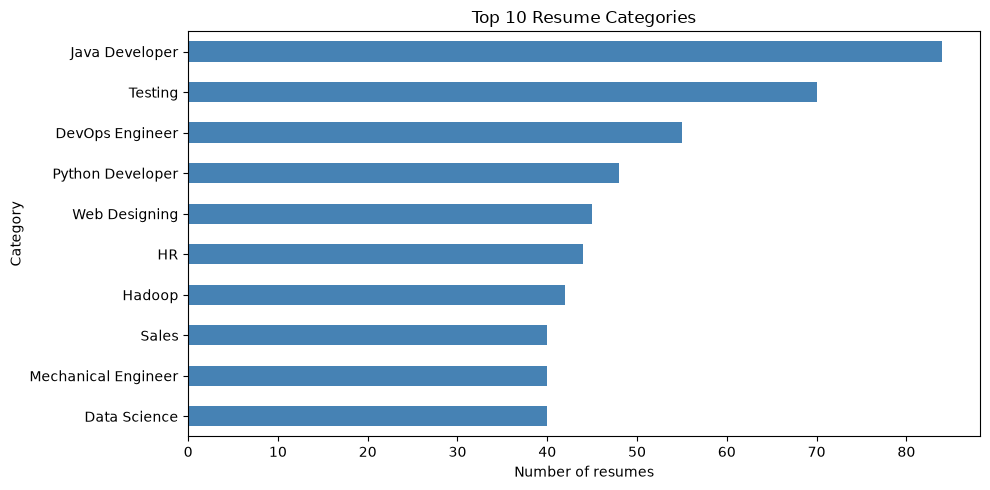

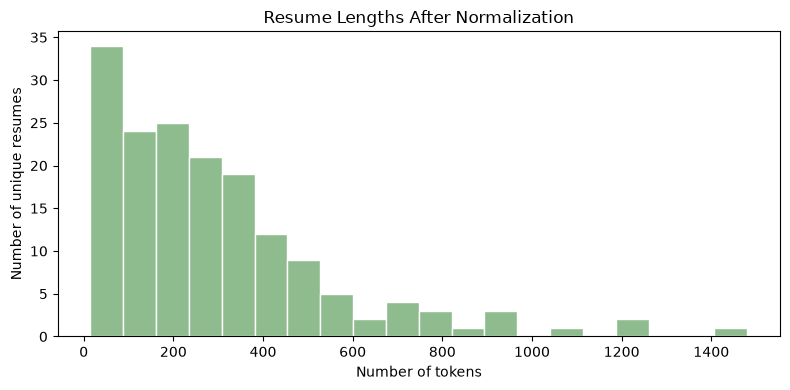

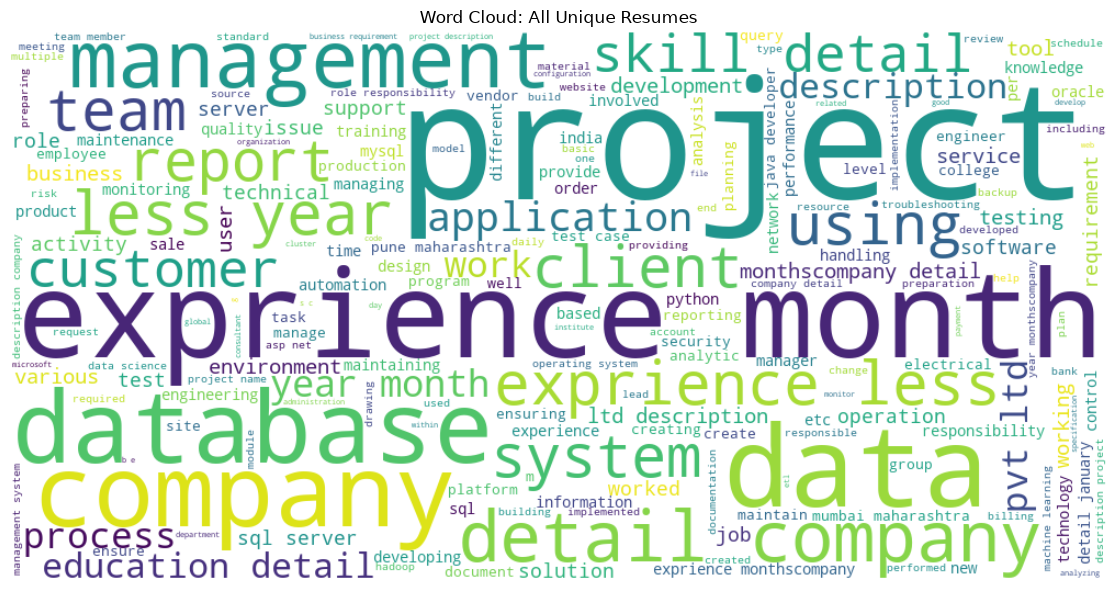

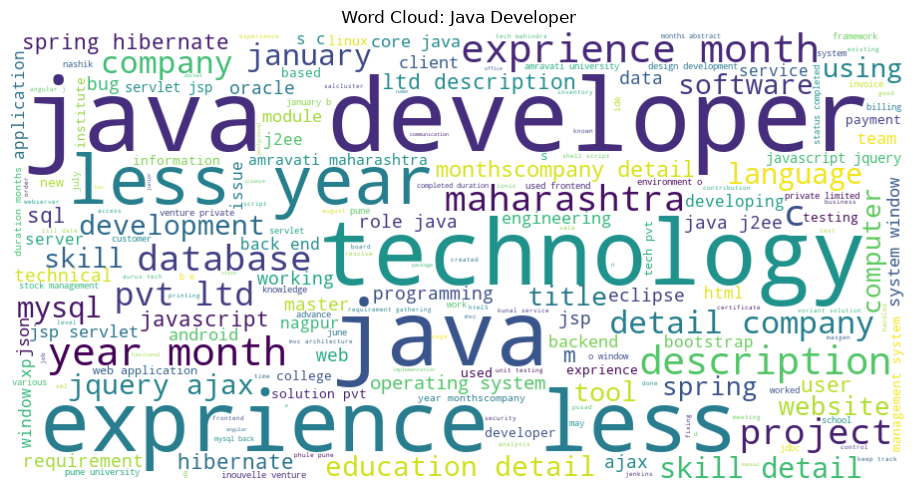

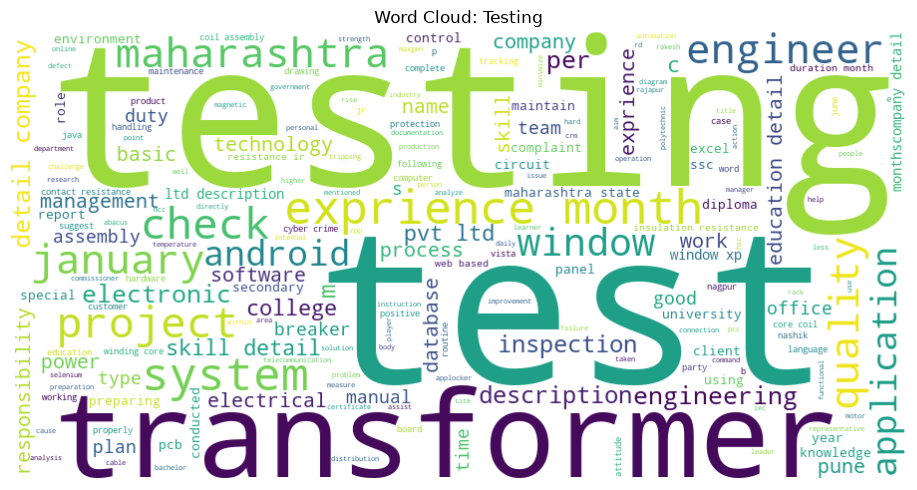

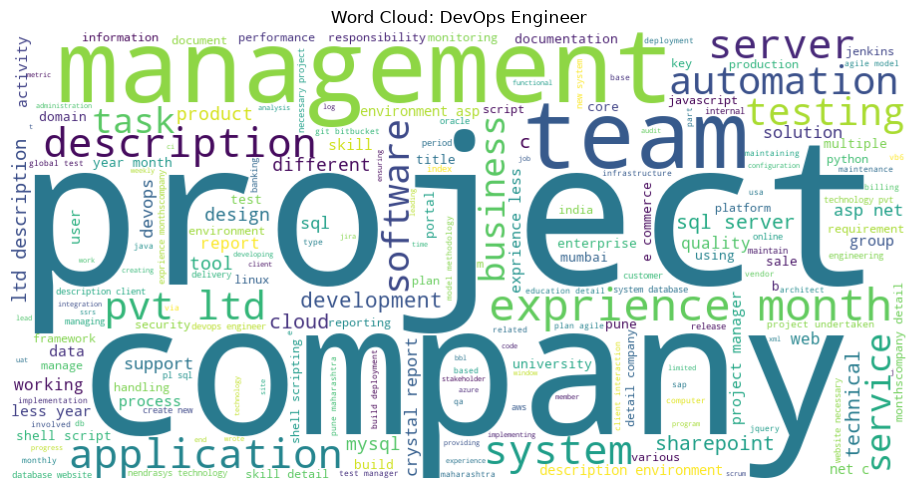

In [9]:
# Make charts from the original rows for category counts, and unique resumes for text summaries.
category_counts = df["Category"].value_counts().head(10)
plt.figure(figsize=(10, 5))
category_counts.sort_values().plot(kind="barh", color="steelblue")
plt.title("Top 10 Resume Categories")
plt.xlabel("Number of resumes")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "top_categories.png", dpi=150)
plt.show()

resume_lengths = unique_df["Tokens"].map(len)
plt.figure(figsize=(8, 4))
plt.hist(resume_lengths, bins=20, color="darkseagreen", edgecolor="white")
plt.title("Resume Lengths After Normalization")
plt.xlabel("Number of tokens")
plt.ylabel("Number of unique resumes")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "resume_lengths.png", dpi=150)
plt.show()

all_words = " ".join(unique_df["Cleaned_Resume"].fillna(""))
cloud = WordCloud(width=1000, height=500, background_color="white", stopwords=STOPWORDS).generate(all_words or "resume")
plt.figure(figsize=(12, 6))
plt.imshow(cloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud: All Unique Resumes")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "all_resumes_wordcloud.png", dpi=150)
plt.show()

# Show word clouds for the three largest categories.
for category in category_counts.head(3).index:
    category_texts = unique_df.loc[unique_df["Category"] == category, "Cleaned_Resume"]
    category_words = " ".join(category_texts.fillna(""))
    if category_words.strip():
        category_cloud = WordCloud(width=900, height=450, background_color="white", stopwords=STOPWORDS).generate(category_words)
        plt.figure(figsize=(10, 5))
        plt.imshow(category_cloud, interpolation="bilinear")
        plt.axis("off")
        plt.title("Word Cloud: " + category)
        plt.tight_layout()
        filename = re.sub(r"[^a-z0-9]+", "_", category.lower()).strip("_") + "_wordcloud.png"
        plt.savefig(FIGURE_DIR / filename, dpi=150)
        plt.show()
print("Figures saved in:", FIGURE_DIR.resolve())
print("Figure files:", sorted(path.name for path in FIGURE_DIR.glob("*.png")))


## 10. Interactive-style demo — experiments 3, 8, and 9
Paste or replace the two example strings below, then run this cell. It prints skills, ranked keywords with scores, similarity, and matched or missing skills. A notebook cell avoids extra interface code while demonstrating the same analysis steps as the project app.

In [10]:
# Replace these sample strings with your own resume and (optionally) job description.
demo_resume = """Data analyst with 4 years of experience using Python, SQL, pandas, scikit-learn,
machine learning, Tableau, AWS, and data visualization. Built dashboards and predictive models."""
demo_job = """Seeking a data analyst with Python, SQL, machine learning, pandas, scikit-learn,
AWS, and strong communication skills."""

demo_skills = find_skills(demo_resume)
demo_score, demo_matched, demo_missing, demo_keywords = compare_resume_to_job(demo_resume, demo_job)
print("Extracted skills:", demo_skills)
print("Top keywords with scores:")
for keyword, score in demo_keywords:
    print(f"  {keyword}: {score:.3f}")
print(f"Match percentage: {demo_score:.1f}%")
print("Matched job skills:", demo_matched)
print("Missing job skills:", demo_missing)


Extracted skills: ['python', 'sql', 'machine learning', 'scikit-learn', 'pandas', 'tableau', 'aws']
Top keywords with scores:
  data: 0.255
  analyst year: 0.179
  aws data: 0.179
  built: 0.179
  built dashboard: 0.179
  dashboard: 0.179
  dashboard predictive: 0.179
  data visualization.: 0.179
  experience: 0.179
  experience using: 0.179
Match percentage: 29.5%
Matched job skills: ['aws', 'machine learning', 'pandas', 'python', 'scikit-learn', 'sql']
Missing job skills: ['communication']
